# Imports

In [1]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from tqdm import tqdm
import subprocess

import os, sys, re
sys.path.append("D:\\DATA\\ActivePIC")
from pathlib import Path

rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# Plot all fundamental modes

In [15]:
from collections import defaultdict
import matplotlib.animation as animation


matplotlib.rcParams["animation.embed_limit"] = 200   # MB; default is 20

mode_dir = Path(rlib.MODE_LIB_DIR)
out_dir = mode_dir / "mode_movies"
out_dir.mkdir(exist_ok=True)
wavs_to_plot = [1.45, 1.65]    # None = every wavelength in the library, or e.g. [1.45, 1.55, 1.65]
zoom = 5.0             # half-window in μm; set to None for the full domain

# Widths available at each wavelength
widths_at = defaultdict(list)
for p in mode_dir.glob("StraightWaveguide_Wav*_Width*.nef"):
    m = re.search(r"_Wav(\d+p\d+)_Width(\d+p\d+)\.nef$", p.name)
    if m:
        wav, width = (float(g.replace("p", ".")) for g in m.groups())
        widths_at[wav].append(width)
if wavs_to_plot is not None:
    widths_at = {w: ws for w, ws in widths_at.items() if np.isclose(w, wavs_to_plot).any()}
if not widths_at:
    raise FileNotFoundError(f"No StraightWaveguide_Wav*_Width*.nef files in {mode_dir}")

for wav in tqdm(sorted(widths_at), desc="Wavelengths"):
    # The mode that mode_field() returns for each width, as signed Ex normalized to its peak
    frames = []
    for width in sorted(widths_at[wav]):
        ex_file, neff = rlib.mode_field(wav, width, mode_dir=str(mode_dir))
        f = rlib.read_mode(ex_file)
        s = f.signed_field()
        frames.append((width, Path(ex_file).suffix, s / np.abs(s).max()))

    extent = (f.x[0], f.x[-1], f.y[0], f.y[-1])
    fig, ax = plt.subplots(figsize=(6, 5.4), dpi=100)
    im = ax.imshow(frames[0][2], extent=extent, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
    if zoom:
        ax.set_xlim(-zoom, zoom)
        ax.set_ylim(-zoom, zoom)
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    fig.colorbar(im, ax=ax, label="$E_x$ (normalized)")
    title = ax.set_title("")
    fig.tight_layout()

    def update(k):
        width, ext, s = frames[k]
        im.set_data(s)
        title.set_text(f"Width = {width:.3f} μm   ({ext})   λ = {wav:.3f} μm")
        return im, title

    anim = animation.FuncAnimation(fig, update, frames=len(frames), blit=False)
    out_html = out_dir / f"Ex_modes_Wav{rlib.param_str(wav)}.html"
    anim.save(out_html, writer=animation.HTMLWriter(fps=4, embed_frames=True))
    plt.close(fig)

print(f"Saved {len(widths_at)} HTML files to {out_dir}")

Wavelengths: 100%|██████████| 2/2 [01:30<00:00, 45.41s/it]

Saved 2 HTML files to D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\mode_movies


# BeamPROP: Scan wavelength

In [43]:
# Define directories and files to work with
device_name = "P-01_StraightReference"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
mode_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\FundamentalMode_lib\\"
save_dir = f"{working_dir}{device_name}_scan_Wav\\"
os.makedirs(save_dir, exist_ok=True)
CAD_filename = f"{device_name}.ind"

# Define parameter scan
wav_arr = np.linspace(1.45, 1.65, 11)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    wav_str = f"{wav:0.3f}".replace(".", "p")
    injection_filename = f'{mode_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00'
    prefix = f'{save_dir}{device_name}_scan_Wav{wav_str}'

    # Set up the parameters
    c = RSoftCircuit()
    c.read(working_dir+CAD_filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Injection_filename", injection_filename)
    c.write(working_dir+CAD_filename)
    
    command = ["bsimw32", "-min", CAD_filename, f"prefix={prefix}",
                   "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    # Save simulation parameters (not comprehensive, some settings are not explicitly given if set to default)
    metadata_name = f'{prefix}.json'
    symbols = rlib.export_symbols(working_dir+CAD_filename, metadata_name)

    # Keep only the necessary output files to save storage
    keep_ext = ['.mon', '.json']
    p = Path(prefix)
    for f in p.parent.glob(p.name + "*"):
        if f.is_file() and f.suffix.lower() not in keep_ext:
            f.unlink()

np.save(f"{save_dir}{device_name}_Wav.npy", wav_arr)

# Plot loss vs. wavelength

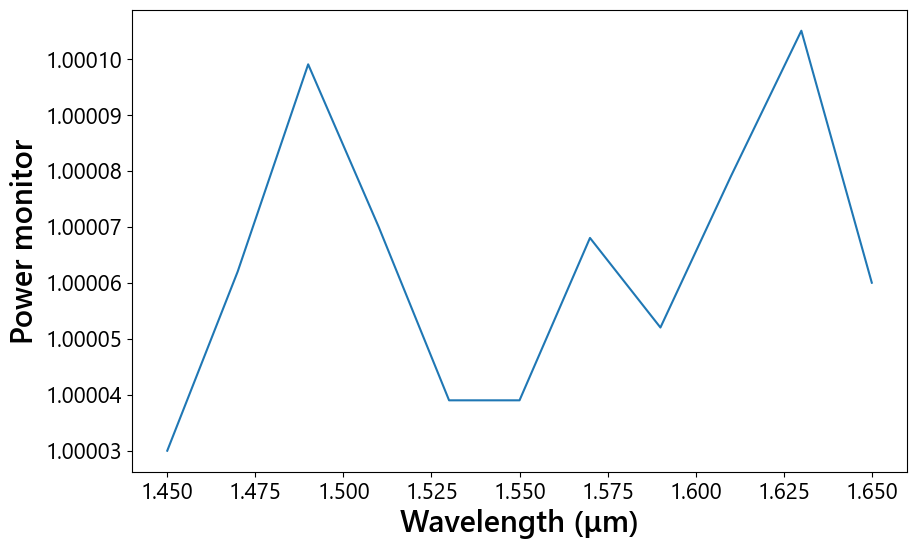

In [50]:
device_name = "P-01_StraightReference"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
save_dir = f"{working_dir}{device_name}_scan_Wav\\"
wav_arr = np.load(f"{save_dir}{device_name}_Wav.npy")
CAD_filename = f"{device_name}.ind"

monitors = []
for wav in wav_arr:
    wav_str = f"{wav:0.3f}".replace(".", "p")
    monitor_filename = f'{save_dir}{device_name}_scan_Wav{wav_str}.mon'
    monitor = rlib.read_monitor(monitor_filename)
    Length = float(rlib.read_symbol(working_dir+CAD_filename, "Length"))
    monitors.append(monitor.values[np.isclose(monitor.z, 16000)].flatten())
monitors = np.array(monitors)

plt.figure(figsize=(10,6))
# plt.plot(wav_arr, (1-monitors[:, 0])*100)
plt.plot(wav_arr, monitors[:, 0])
plt.xlabel('Wavelength (μm)')
# plt.ylabel('Loss (%)')
plt.ylabel('Power monitor')
ax = plt.gca()
ax.ticklabel_format(axis="y", useOffset=False, style="plain")
plt.show()